# CODE 1.2: Split the Time and Label Every Reading

> **Goal:** split the 7 months into a train, a validation and a test part, and give every reading a label: *healthy*, *warning zone*, *leak* or *ignored*. These rules decide later how the two models are judged, so they are fixed here, before any model exists and before anyone has looked at the test months.
>
> - **Input:** `data/processed/metropt3.parquet` (from notebook 1.1), and the list of the 4 air leaks in `Data Description_Metro.pdf`.
> - **Output:**
>   - `results/time_split.csv`: the three parts of the time.
>   - `results/leaks.csv`: the 4 leaks with their zones.
>   - `data/processed/labels.parquet`: the part and the zone of every reading.
>
> At the end you should see **ALL CHECKS PASSED**.
>
> This notebook reads **only the timestamps**, never a sensor value. The labels come from the official list of leaks, not from the data.

### Words Used in This Notebook

> - **Train / validation / test:** the three parts of the time. Train is where a model learns, validation is where we tune it, and test is where we judge it, once, at the end.
> - **Data leakage:** when information from the test part sneaks into training or tuning. Then the test result looks better than the model really is.
> - **Air leak:** air escapes somewhere after the compressor. The official list has 4 of them, all in the test months.
> - **Warning zone:** the 24 hours before a leak starts. An alarm there counts as a warning for that leak.
> - **Lead time:** how many hours the first warning came before the leak started.
> - **False alarm:** an alarm while the machine is healthy.
> - **Ignored zone:** the 48 hours after the reported end of a leak. Alarms there count neither as right nor as false.
> - **Label:** a short name we attach to every reading, for example *healthy* or *warning*.

## Import Libraries & Variables

### Import Libraries

> - `os`: works with folders and file paths.
> - `numpy`: works with numbers.
> - `pandas`: works with tables and with dates and times.
> - `matplotlib`: draws charts. `matplotlib.dates` writes the dates under a time axis.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

### Variables

#### Folder Paths

> - `ROOT_DIR`: the main project folder (the folder with `requirements.txt`).
> - `PROCESSED_DIR`: tables that the notebooks make from the raw data.
> - `RESULTS_DIR`: small result files that belong in the repository, so anyone can see the rules.
> - `PARQUET_FILE`: the data saved by notebook 1.1.
> - `LABELS_FILE`, `SPLIT_FILE`, `LEAKS_FILE`: the three files this notebook saves.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
PARQUET_FILE = os.path.join(PROCESSED_DIR, "metropt3.parquet")
LABELS_FILE = os.path.join(PROCESSED_DIR, "labels.parquet")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
LEAKS_FILE = os.path.join(RESULTS_DIR, "leaks.csv")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### The Time Split

> Each part starts at its first date and stops just before its second date. So train is every reading from 1 February 00:00 up to, but not including, 1 March 00:00. The test part goes to 2 September, the day after the last reading.

In [3]:
SPLITS = {
    "train": ("2020-02-01", "2020-03-01"),
    "validation": ("2020-03-01", "2020-04-01"),
    "test": ("2020-04-01", "2020-09-02"),
}

#### The Four Air Leaks

> Copied from the table "Failure Information" in `Data Description_Metro.pdf`. In the PDF the dates are written month first (`4/18/2020` is 18 April 2020). All 4 are an "Air Leak" with severity "High stress".
>
> - `LEAKS`: the start, the end and the maintenance note (*Report*) of each leak.
> - `REPAIRS`: the repair times from the notes that we can use. The note of leak 2 says "30Apr", which is a month *before* that leak, so that date cannot be right and we leave it out. Leak 1 has no note.

In [4]:
LEAKS = pd.DataFrame({
    "leak": [1, 2, 3, 4],
    "start": pd.to_datetime(["2020-04-18 00:00", "2020-05-29 23:30", "2020-06-05 10:00", "2020-07-15 14:30"]),
    "end": pd.to_datetime(["2020-04-18 23:59", "2020-05-30 06:00", "2020-06-07 14:30", "2020-07-15 19:00"]),
    "report": ["", "Maintenance on 30Apr at 12:00", "Maintenance on 8Jun at 16:00", "Maintenance on 16Jul at 00:00"],
})
REPAIRS = {3: "2020-06-08 16:00", 4: "2020-07-16 00:00"}

#### Zone Rules

> - `WARNING_HOURS`: the warning zone is the 24 hours before a leak starts.
> - `IGNORED_HOURS`: the ignored zone is the 48 hours after the reported end of a leak.
> - `GAP_SECONDS`: as in notebook 1.1, a step of more than 60 seconds between two readings is a gap. We need it to count the hours that really have data.
> - `ZONE_ORDER`, `SPLIT_ORDER`: the order in which the tables and charts list the zones and the parts.
> - `COLORS`: one color per part and per zone, used in the charts.

In [5]:
WARNING_HOURS = 24
IGNORED_HOURS = 48
GAP_SECONDS = 60
ZONE_ORDER = ["healthy", "warning", "leak", "ignored"]
SPLIT_ORDER = ["train", "validation", "test"]
COLORS = {"train": "#E1F5EE", "validation": "#EEEDFE", "test": "#F1EFE8",
          "warning": "#EF9F27", "leak": "#E24B4A", "ignored": "#B4B2A9"}

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`, with the name of the check as the key.

In [6]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Which Part Is a Time In?

> `split_of()` gives every time the name of its part. A time that is in no part gets `none`, so we can count those.

In [7]:
def split_of(times, splits):
    names = pd.Series("none", index=times.index)
    for name, (start, end) in splits.items():
        names[(times >= start) & (times < end)] = name
    return names

### Which Zone Is a Time In?

> `zone_of()` starts with *healthy* for every time. Then, for each leak, it marks three stretches of time:
>
> - **warning**: from 24 hours before the start, up to the start.
> - **leak**: from the start to the end, both included.
> - **ignored**: from just after the end, up to 48 hours after the end.
>
> It returns two columns: the zone, and the number of the leak the zone belongs to (0 for healthy).

In [8]:
def zone_of(times, leaks, warning_hours, ignored_hours):
    zones = pd.Series("healthy", index=times.index)
    leak_numbers = pd.Series(0, index=times.index, dtype="int8")
    for row in leaks.itertuples():
        stretches = {
            "warning": (times >= row.start - pd.Timedelta(hours=warning_hours)) & (times < row.start),
            "leak": (times >= row.start) & (times <= row.end),
            "ignored": (times > row.end) & (times <= row.end + pd.Timedelta(hours=ignored_hours)),
        }
        for zone, inside in stretches.items():
            zones[inside] = zone
            leak_numbers[inside] = row.leak
    return zones, leak_numbers

### Hours That Really Have Data

> `hours_of_data()` adds up the steps between readings for the rows in `inside`, without the gaps, and turns seconds into hours. So a zone of 24 hours with a night gap has fewer than 24 hours of data.

In [9]:
def hours_of_data(steps, inside, gap_seconds):
    return steps[inside & (steps <= gap_seconds)].sum() / 3600

## Load the Timestamps

### Only the Time Column

> `columns=["timestamp"]` reads just the time of every reading from the Parquet file, and none of the 15 signals. `steps` is the number of seconds from each reading to the next one, as in notebook 1.1.

In [10]:
df_labels = pd.read_parquet(PARQUET_FILE, columns=["timestamp"])
steps = df_labels["timestamp"].diff().dt.total_seconds()
print(f"Readings: {len(df_labels):,}")
print("First:", df_labels["timestamp"].iloc[0], "| last:", df_labels["timestamp"].iloc[-1])
print("Columns read:", list(df_labels.columns))

Readings: 1,516,948
First: 2020-02-01 00:00:00 | last: 2020-09-01 03:59:50
Columns read: ['timestamp']


## Split the Time

### Why Three Parts, and Why by Time

> Think of a school exam:
>
> - **train (February)** is the practice book. The models learn what a healthy compressor looks like.
> - **validation (March)** is the try-out. Still healthy. Here we set the alarm limits (notebook 5.1) and decide when the LSTM stops training (notebook 4.2).
> - **test (April to the end)** is the real exam, with all 4 leaks. It is opened once, in notebook 5.2, after all rules are locked.
>
> We split by **time** and not at random. A model in real use is always trained on the past and then used on the future. A random split would put test minutes right next to training minutes, and two readings 10 seconds apart are almost the same. The model would then have practically seen the test before the exam: data leakage.

In [11]:
df_labels["split"] = split_of(times=df_labels["timestamp"], splits=SPLITS)

split_table = (df_labels.groupby("split", sort=False)
               .agg(first_reading=("timestamp", "min"), last_reading=("timestamp", "max"), readings=("timestamp", "size"))
               .reindex(SPLIT_ORDER))
split_table["hours_of_data"] = [round(hours_of_data(steps=steps, inside=df_labels["split"] == name, gap_seconds=GAP_SECONDS), 1) for name in SPLIT_ORDER]
display(split_table)

,first_reading,last_reading,readings,hours_of_data
split,,,,
train,2020-02-01 00:00:00,2020-02-28 23:57:08,214850,591.5
validation,2020-03-01 04:00:09,2020-03-31 23:59:59,230448,634.5
test,2020-04-01 00:00:09,2020-09-01 03:59:50,1071650,2980.5


> These checks test the split with the months of the readings themselves, not with the dates in `SPLITS`.

In [12]:
months = df_labels.groupby("split")["timestamp"].apply(lambda times: sorted(times.dt.month.unique().tolist()))
print("Months in each part:", months.reindex(SPLIT_ORDER).to_dict(), "\n")

check("every reading is in exactly one part", (df_labels["split"] != "none").all())
check("train holds only February readings", months["train"] == [2])
check("validation holds only March readings", months["validation"] == [3])
check("test holds only readings from April or later", min(months["test"]) >= 4)
check("the parts follow each other in time: train, then validation, then test",
      split_table["last_reading"]["train"] < split_table["first_reading"]["validation"]
      and split_table["last_reading"]["validation"] < split_table["first_reading"]["test"])

Months in each part: {'train': [2], 'validation': [3], 'test': [4, 5, 6, 7, 8, 9]} 

PASS  every reading is in exactly one part
PASS  train holds only February readings
PASS  validation holds only March readings
PASS  test holds only readings from April or later
PASS  the parts follow each other in time: train, then validation, then test


## The Four Air Leaks

### The Leak Table

> Two small mistakes in the PDF table, so you are not surprised when you open it:
>
> - The second row is numbered "#1" again. The rows are in time order and the others are #1, #3 and #4, so it is leak #2.
> - The note of leak 2 says "Maintenance on 30Apr", a month before that leak started. That date cannot be right, so `REPAIRS` leaves it out.

In [13]:
leaks = LEAKS.copy()
leaks["hours_long"] = ((leaks["end"] - leaks["start"]).dt.total_seconds() / 3600).round(1)
display(leaks)

test_start, test_end = (pd.Timestamp(day) for day in SPLITS["test"])
check("there are 4 leaks", len(leaks) == 4)
check("every leak starts before it ends", (leaks["start"] < leaks["end"]).all())
check("the leaks are in time order", leaks["start"].is_monotonic_increasing)
check("every leak is in the test part", ((leaks["start"] >= test_start) & (leaks["end"] < test_end)).all())

,leak,start,end,report,hours_long
0,1,2020-04-18 00:00:00,2020-04-18 23:59:00,,24.0
1,2,2020-05-29 23:30:00,2020-05-30 06:00:00,Maintenance on 30Apr at 12:00,6.5
2,3,2020-06-05 10:00:00,2020-06-07 14:30:00,Maintenance on 8Jun at 16:00,52.5
3,4,2020-07-15 14:30:00,2020-07-15 19:00:00,Maintenance on 16Jul at 00:00,4.5


PASS  there are 4 leaks
PASS  every leak starts before it ends
PASS  the leaks are in time order
PASS  every leak is in the test part


### Warning Zone and Lead Time

> How a model is judged around one leak:
>
> - **Caught:** the model gave an alarm in the warning zone (the 24 hours before the start) or during the leak.
> - **Lead time:** the time from that first alarm to the start of the leak. If the first alarm only comes after the start, the leak is still caught, but the lead time is negative: the warning came late.
> - **False alarm:** an alarm while the machine is healthy. They are counted per week.
>
> Think of a weather app. It says at 12:00 "rain at 15:00", and it rains at 15:00: you had 3 hours to bring in the laundry. That is a lead time of 3 hours. But an app that says "rain" every day of the week, until it finally rains on day 7, did not warn you 7 days early. It gave 6 false alarms. The warning zone is the rule that stops a "chatty" model from claiming a long lead time. The picture shows it with two made-up models.
>
> **Why 24 hours?** It gives the maintenance team about one working day to get ready, and it is short enough that an alarm in it clearly belongs to this leak. It is a limit, not a goal: a warning 2 hours before the start is caught, with a lead time of 2 hours.

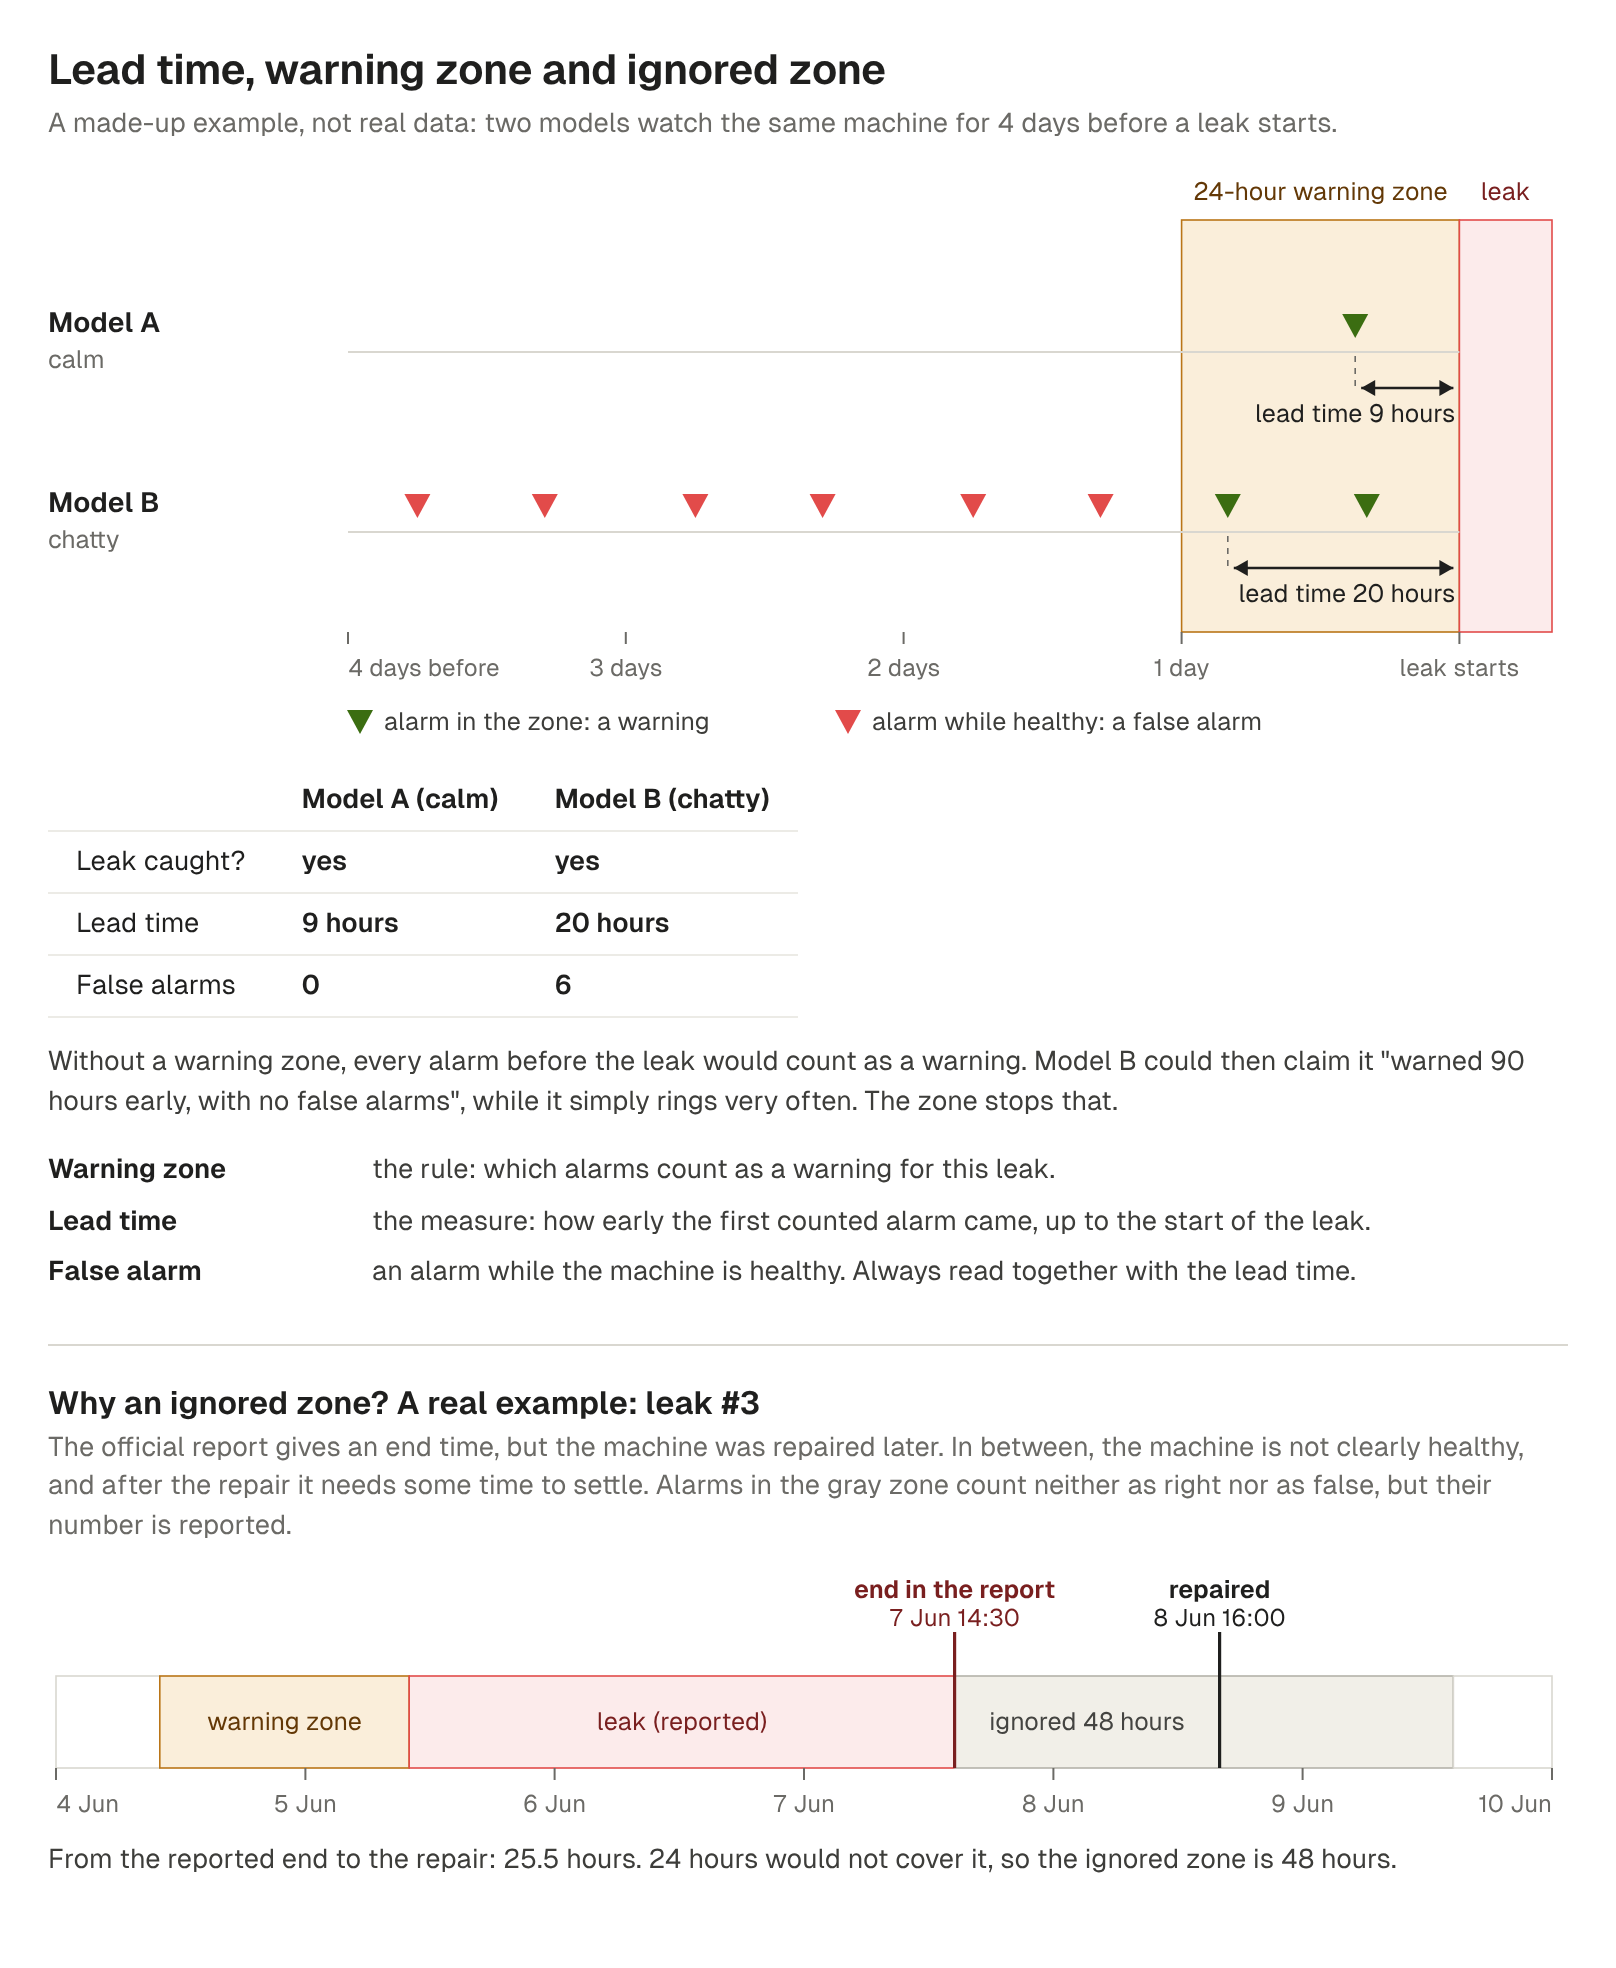

### Why the Ignored Zone Is 48 Hours

> After the reported end of a leak, the machine is not clearly healthy: it may still wait for its repair, and after the repair it needs some time to settle. An alarm there should not count as a false alarm, and not as a warning either. So we ignore these hours, but we still count the alarms there and report them in notebook 5.2, so nothing is hidden.
>
> How long must the ignored zone be? The table below measures the time from the reported end to the repair in the notes.

In [14]:
repairs = LEAKS[["leak", "end"]].copy()
repairs["repair_in_note"] = pd.to_datetime(repairs["leak"].map(REPAIRS))
repairs["hours_end_to_repair"] = ((repairs["repair_in_note"] - repairs["end"]).dt.total_seconds() / 3600).round(1)
display(repairs)

longest = repairs["hours_end_to_repair"].max()
print(f"Longest time from the reported end to the repair: {longest} hours\n")
check(f"every usable repair is inside the {IGNORED_HOURS}-hour ignored zone", (repairs["hours_end_to_repair"].dropna() <= IGNORED_HOURS).all())

,leak,end,repair_in_note,hours_end_to_repair
0,1,2020-04-18 23:59:00,NaT,NaN
1,2,2020-05-30 06:00:00,NaT,NaN
2,3,2020-06-07 14:30:00,2020-06-08 16:00:00,25.5
3,4,2020-07-15 19:00:00,2020-07-16 00:00:00,5.0


Longest time from the reported end to the repair: 25.5 hours

PASS  every usable repair is inside the 48-hour ignored zone


> **What we see:** for leak 3 the repair came more than a day after the reported end. An ignored zone of 24 hours would end before that repair, so alarms of a still broken machine would be counted as false alarms. With 48 hours, both usable repairs are inside the zone, with time left for the machine to settle.

## Label Every Reading

### Give Every Reading Its Zone

> `zone_of()` labels all readings. Then we count, for each part and zone, the readings and the hours that really have data.

In [15]:
df_labels["zone"], df_labels["leak"] = zone_of(times=df_labels["timestamp"], leaks=LEAKS,
                                               warning_hours=WARNING_HOURS, ignored_hours=IGNORED_HOURS)

readings = pd.crosstab(df_labels["split"], df_labels["zone"]).reindex(index=SPLIT_ORDER, columns=ZONE_ORDER, fill_value=0)
hours = pd.DataFrame({zone: [round(hours_of_data(steps=steps, inside=(df_labels["split"] == name) & (df_labels["zone"] == zone),
                                                 gap_seconds=GAP_SECONDS), 1) for name in SPLIT_ORDER] for zone in ZONE_ORDER},
                     index=SPLIT_ORDER)
print("Readings per part and zone:")
display(readings)
print("Hours of data per part and zone:")
display(hours)

Readings per part and zone:


zone,healthy,warning,leak,ignored
split,,,,
train,214850,0,0,0
validation,230448,0,0,0
test,955899,28668,29954,57129


Hours of data per part and zone:


,healthy,warning,leak,ignored
train,591.5,0.0,0.0,0.0
validation,634.5,0.0,0.0,0.0
test,2655.8,81.5,82.5,160.7


> Checks on the labels:
>
> - Train and validation must be fully *healthy*, because the models learn and are tuned there.
> - The zones of two different leaks must not overlap: the ignored zone of one leak ends before the warning zone of the next one starts.
> - A *healthy* reading belongs to no leak (number 0), and every other reading belongs to a leak (1 to 4).

In [16]:
zone_starts = LEAKS["start"] - pd.Timedelta(hours=WARNING_HOURS)
zone_ends = LEAKS["end"] + pd.Timedelta(hours=IGNORED_HOURS)
gaps_between = (zone_starts.iloc[1:].values - zone_ends.iloc[:-1].values) / pd.Timedelta(hours=1)
print("Hours between the ignored zone of one leak and the warning zone of the next:", np.round(gaps_between, 1).tolist(), "\n")

healthy = df_labels["zone"] == "healthy"
check("train and validation hold only healthy readings", healthy[df_labels["split"].isin(["train", "validation"])].all())
check("the zones of different leaks do not overlap", (gaps_between > 0).all())
check("healthy readings belong to no leak, all other readings to leak 1 to 4",
      (df_labels.loc[healthy, "leak"] == 0).all() and df_labels.loc[~healthy, "leak"].between(1, 4).all())

Hours between the ignored zone of one leak and the warning zone of the next: [911.5, 76.0, 840.0] 

PASS  train and validation hold only healthy readings
PASS  the zones of different leaks do not overlap
PASS  healthy readings belong to no leak, all other readings to leak 1 to 4


### The Whole Timeline

> The three parts as colored backgrounds, and the zones of the 4 leaks on top. Only times are drawn here, no sensor values.

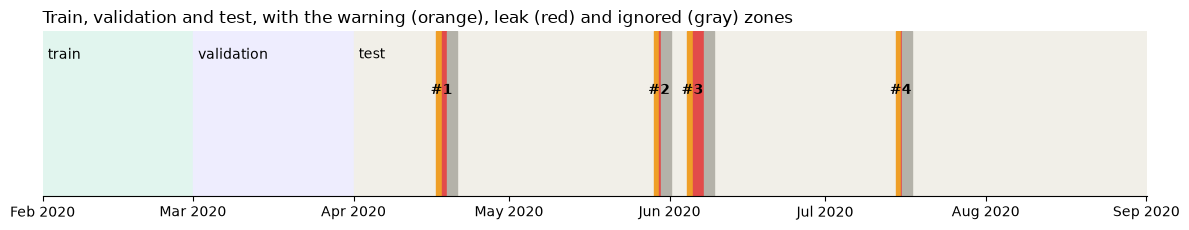

In [17]:
fig, ax = plt.subplots(figsize=(12, 2.4))
for name, (start, end) in SPLITS.items():
    ax.axvspan(pd.Timestamp(start), min(pd.Timestamp(end), df_labels["timestamp"].iloc[-1]), color=COLORS[name], zorder=0)
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=1), 0.9, name, fontsize=10, va="top")
for row in LEAKS.itertuples():
    ax.axvspan(row.start - pd.Timedelta(hours=WARNING_HOURS), row.start, color=COLORS["warning"], zorder=1)
    ax.axvspan(row.start, row.end, color=COLORS["leak"], zorder=1)
    ax.axvspan(row.end, row.end + pd.Timedelta(hours=IGNORED_HOURS), color=COLORS["ignored"], zorder=1)
    ax.text(row.start, 0.62, f"#{row.leak}", fontsize=10, ha="center", fontweight="bold")
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlim(df_labels["timestamp"].iloc[0], df_labels["timestamp"].iloc[-1])
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Train, validation and test, with the warning (orange), leak (red) and ignored (gray) zones", loc="left")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### Each Leak Up Close

> One chart per leak, from 12 hours before its warning zone to 12 hours after its ignored zone. The dark strip at the bottom shows when there are readings: where it is missing, the train was switched off and no model can see anything. The black line is the repair from the notes. Again, only times are drawn.

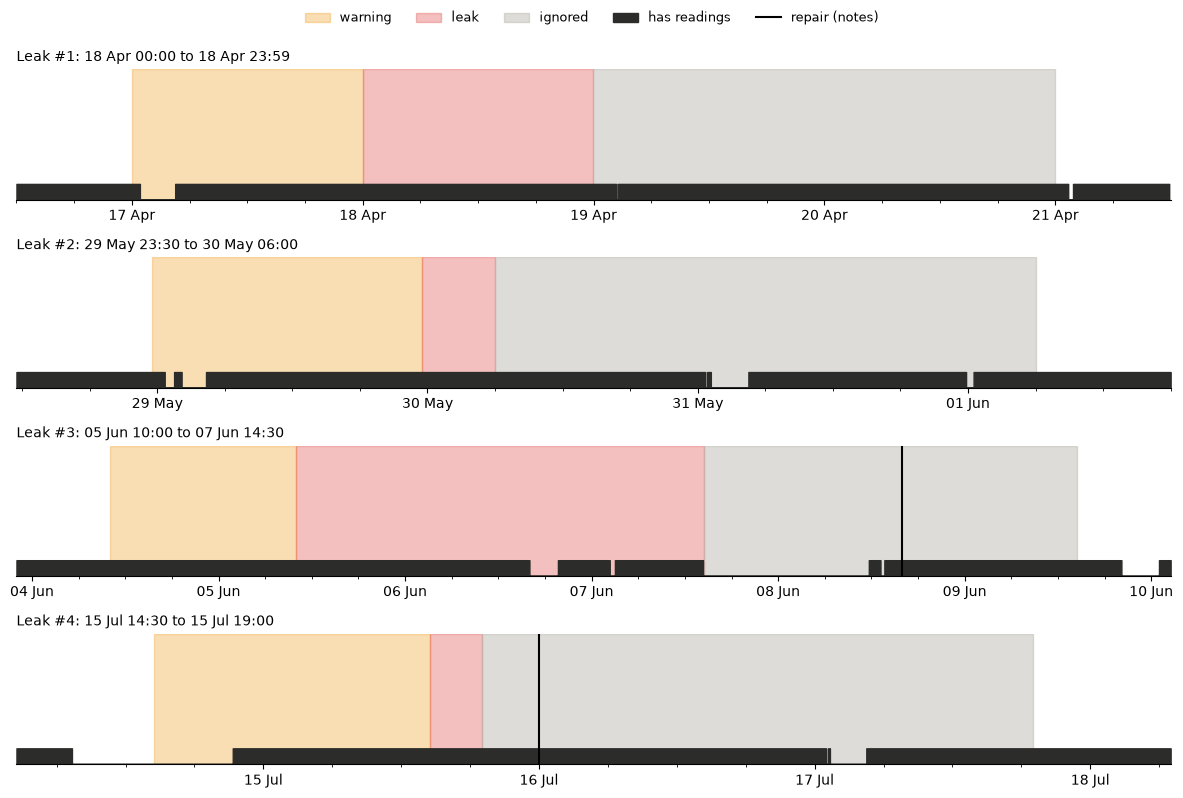

In [18]:
fig, axes = plt.subplots(len(LEAKS), 1, figsize=(12, 2.0 * len(LEAKS)))
for ax, row in zip(axes, LEAKS.itertuples()):
    left = row.start - pd.Timedelta(hours=WARNING_HOURS + 12)
    right = row.end + pd.Timedelta(hours=IGNORED_HOURS + 12)
    ax.axvspan(row.start - pd.Timedelta(hours=WARNING_HOURS), row.start, color=COLORS["warning"], alpha=0.35, label="warning")
    ax.axvspan(row.start, row.end, color=COLORS["leak"], alpha=0.35, label="leak")
    ax.axvspan(row.end, row.end + pd.Timedelta(hours=IGNORED_HOURS), color=COLORS["ignored"], alpha=0.45, label="ignored")
    near = df_labels["timestamp"].between(left, right)
    has_data = df_labels.loc[near, "timestamp"].dt.floor("10min").value_counts().reindex(pd.date_range(left.floor("10min"), right, freq="10min"), fill_value=0) > 0
    ax.fill_between(has_data.index, 0, 0.12 * has_data.values, step="post", color="#2C2C2A", label="has readings")
    if row.leak in REPAIRS:
        ax.axvline(pd.Timestamp(REPAIRS[row.leak]), color="black", linewidth=1.5, label="repair (notes)")
    ax.set_xlim(left, right)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_title(f"Leak #{row.leak}: {row.start:%d %b %H:%M} to {row.end:%d %b %H:%M}", loc="left", fontsize=10)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
handles, names = axes[list(LEAKS["leak"]).index(min(REPAIRS))].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

> The same in numbers: for each leak, how many hours of each zone really have readings.

In [19]:
per_leak = pd.DataFrame({zone: [round(hours_of_data(steps=steps, inside=(df_labels["leak"] == number) & (df_labels["zone"] == zone),
                                                    gap_seconds=GAP_SECONDS), 1) for number in LEAKS["leak"]] for zone in ["warning", "leak", "ignored"]},
                        index=pd.Index(LEAKS["leak"], name="leak"))
per_leak["zone length (warning / leak / ignored)"] = [f"{WARNING_HOURS} / {hours:.1f} / {IGNORED_HOURS}" for hours in leaks["hours_long"]]
print("Hours of data in each zone of each leak:")
display(per_leak)

Hours of data in each zone of each leak:


,warning,leak,ignored,zone length (warning / leak / ignored)
leak,,,,
1,19.9,23.9,47.6,24 / 24.0 / 48
2,20.5,6.5,43.3,24 / 6.5 / 48
3,24.0,47.7,26.1,24 / 52.5 / 48
4,17.0,4.5,43.7,24 / 4.5 / 48


> **What we see:**
>
> - Not every hour of the zones has readings. For example, the warning zone of leak 4 has 17.0 of its 24 hours with data: the train was switched off for part of it. While there are no readings, no model can give an alarm. This is the same for both models, so the comparison stays fair.
> - For leak 3 the readings stop shortly before the reported end, and only come back the next day, a few hours before the repair (see the chart). The train was probably taken out of service.
>
> These are facts about the data, not about the models. Notebook 5.2 keeps them in mind when it reads the lead times.

## Save

### Save the Rules and the Labels

> - `results/time_split.csv` and `results/leaks.csv` are small and go into the repository: everyone can check the rules that judge the models.
> - `data/processed/labels.parquet` has one row per reading, in the same order as `metropt3.parquet`. Only notebook 3.1 (for the parts) and notebook 5.2 (for the zones) read it. The models never see it.
>
> The text columns become *categories*: pandas stores each name once and gives every row a small number instead. That keeps the file small. Then every file is read back and compared.

In [20]:
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

df_labels["split"] = pd.Categorical(df_labels["split"], categories=SPLIT_ORDER)
df_labels["zone"] = pd.Categorical(df_labels["zone"], categories=ZONE_ORDER)
df_labels.to_parquet(LABELS_FILE, index=False)

split_file = pd.DataFrame({"split": SPLIT_ORDER, "from": [SPLITS[name][0] for name in SPLIT_ORDER], "until (not included)": [SPLITS[name][1] for name in SPLIT_ORDER]})
split_file = split_file.join(split_table.reset_index(drop=True))
split_file.to_csv(SPLIT_FILE, index=False)

leaks_file = LEAKS.copy()
leaks_file["warning_from"] = leaks_file["start"] - pd.Timedelta(hours=WARNING_HOURS)
leaks_file["ignored_until"] = leaks_file["end"] + pd.Timedelta(hours=IGNORED_HOURS)
leaks_file = leaks_file[["leak", "warning_from", "start", "end", "ignored_until", "report"]]
leaks_file.to_csv(LEAKS_FILE, index=False)

for path in [LABELS_FILE, SPLIT_FILE, LEAKS_FILE]:
    print(f"Saved: {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1024:.1f} KB)")
display(leaks_file)

Saved: data\processed\labels.parquet (9809.4 KB)
Saved: results\time_split.csv (0.3 KB)
Saved: results\leaks.csv (0.5 KB)


,leak,warning_from,start,end,ignored_until,report
0,1,2020-04-17 00:00:00,2020-04-18 00:00:00,2020-04-18 23:59:00,2020-04-20 23:59:00,
1,2,2020-05-28 23:30:00,2020-05-29 23:30:00,2020-05-30 06:00:00,2020-06-01 06:00:00,Maintenance on 30Apr at 12:00
2,3,2020-06-04 10:00:00,2020-06-05 10:00:00,2020-06-07 14:30:00,2020-06-09 14:30:00,Maintenance on 8Jun at 16:00
3,4,2020-07-14 14:30:00,2020-07-15 14:30:00,2020-07-15 19:00:00,2020-07-17 19:00:00,Maintenance on 16Jul at 00:00


In [21]:
labels_back = pd.read_parquet(LABELS_FILE)
leaks_back = pd.read_csv(LEAKS_FILE, parse_dates=["warning_from", "start", "end", "ignored_until"], keep_default_na=False)
split_back = pd.read_csv(SPLIT_FILE)
times = pd.read_parquet(PARQUET_FILE, columns=["timestamp"])["timestamp"]

check("labels.parquet has exactly the table in memory", labels_back.equals(df_labels))
check("labels.parquet has the same timestamps, in the same order, as metropt3.parquet", labels_back["timestamp"].equals(times))
check("leaks.csv has the 4 leaks with their zones", leaks_back.equals(leaks_file))
check("time_split.csv has the 3 parts", split_back["split"].tolist() == SPLIT_ORDER)

PASS  labels.parquet has exactly the table in memory
PASS  labels.parquet has the same timestamps, in the same order, as metropt3.parquet
PASS  leaks.csv has the 4 leaks with their zones
PASS  time_split.csv has the 3 parts


## Result

### Final Result

> If every check passed, the rules are fixed and every reading has its label. If a check failed, its name is printed.

In [22]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (17 checks)


## Summary

> - The time is split into **train** (February), **validation** (March) and **test** (April to the end). It is split by time, because a model is always trained on the past and used on the future.
> - All 4 air leaks are in the test part, so train and validation are fully healthy.
> - Every reading has a zone: *healthy*, *warning* (24 hours before a leak), *leak*, or *ignored* (48 hours after the reported end, because a repair can come more than a day later).
> - The rules are saved in `results/time_split.csv` and `results/leaks.csv` before any model exists. The labels are in `data/processed/labels.parquet`, and only notebooks 3.1 and 5.2 read them.
> - This notebook used only timestamps. The sensor values of the test months are still unseen.
>
> **Next:** `notebooks/2_eda/2.1_explore_normal_behavior.ipynb`